# 01 — RAVDESS: Dataset Exploration

**Aim.** Inspect the dataset structure before extracting acoustic features. We analyze label counts, actor composition, recording duration, and the `intensity` design.

**Data.** Audio-only speech subset of RAVDESS: 24 actors, 8 emotions, 1,440 WAV files. This stage does not train models. A separate actor-disjoint split is specified in notebook `04`.

## 1. Load audio metadata

In [ ]:
from pathlib import Path
import zipfile

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import soundfile as sf
from google.colab import drive
from IPython.display import display

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/speech-emotion-recognition-project-d')
ZIP_PATH = PROJECT_DIR / 'data/Audio_Speech_Actors_01-24.zip'
EXTRACT_DIR = Path('/content/ravdess_speech')
METADATA_PATH = PROJECT_DIR / 'data/processed/ravdess_metadata.csv'
FIGURES_DIR = PROJECT_DIR / 'results/figures/01_eda'

PURPLE, LAVENDER, MUTED = '#B57EDC', '#DFC6EE', '#A9BDCE'
plt.rcParams.update({
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 16,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.spines.left': False, 'axes.axisbelow': True,
})

assert ZIP_PATH.is_file(), f'Missing RAVDESS archive: {ZIP_PATH}'
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
if len(list(EXTRACT_DIR.rglob('*.wav'))) != 1440:
    with zipfile.ZipFile(ZIP_PATH) as archive:
        archive.extractall(EXTRACT_DIR)

audio_files = sorted(EXTRACT_DIR.rglob('*.wav'))
actor_ids = {int(p.stem.split('-')[-1]) for p in audio_files}
print(f'Total audio files: {len(audio_files)}')
print(f'Total actors: {len(actor_ids)}')
print(f'Example: {audio_files[0].name if audio_files else "No files found"}')
assert len(audio_files) == 1440 and len(actor_ids) == 24
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total audio files: 1440
Total actors: 24
Example: 03-01-01-01-01-01-01.wav


In [ ]:
EMOTIONS = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
emotion_map = {f'{i:02d}': label for i, label in enumerate(EMOTIONS, start=1)}

records = []
for path in audio_files:
    parts = path.stem.split('-')
    assert len(parts) == 7, f'Unexpected RAVDESS filename: {path.name}'
    _, _, emotion, intensity, statement, repetition, actor = parts
    info = sf.info(str(path))
    actor_id = int(actor)
    records.append({
        'relative_path': str(path.relative_to(EXTRACT_DIR)),
        'emotion': emotion_map[emotion],
        'emotion_id': int(emotion),
        'actor_id': actor_id,
        'gender': 'male' if actor_id % 2 else 'female',
        'intensity': int(intensity),
        'statement': int(statement),
        'repetition': int(repetition),
        'duration_sec': info.duration,
        'sample_rate': info.samplerate,
    })

df = pd.DataFrame(records).sort_values('relative_path').reset_index(drop=True)
assert df.relative_path.is_unique
assert df.actor_id.nunique() == 24
assert set(df.emotion) == set(EMOTIONS)
assert (df.groupby('actor_id').size() == 60).all()
print(f'Dataset shape: {df.shape}')
display(df.head())

Dataset shape: (1440, 10)


,relative_path,emotion,emotion_id,actor_id,gender,intensity,statement,repetition,duration_sec,sample_rate
0,Actor_01/03-01-01-01-01-01-01.wav,neutral,1,1,male,1,1,1,3.303292,48000
1,Actor_01/03-01-01-01-01-02-01.wav,neutral,1,1,male,1,1,2,3.336667,48000
2,Actor_01/03-01-01-01-02-01-01.wav,neutral,1,1,male,1,2,1,3.269917,48000
3,Actor_01/03-01-01-01-02-02-01.wav,neutral,1,1,male,1,2,2,3.169833,48000
4,Actor_01/03-01-02-01-01-01-01.wav,calm,2,1,male,1,1,1,3.536854,48000


### Data quality checks

In [ ]:
missing = df.isna().sum()
print(f'Missing values: {missing.sum()}')
display(missing.to_frame('missing'))
print(f'Duplicate rows: {df.duplicated().sum()}')

Missing values: 0


,missing
relative_path,0
emotion,0
emotion_id,0
actor_id,0
gender,0
intensity,0
statement,0
repetition,0
duration_sec,0
sample_rate,0


Duplicate rows: 0


## 2. Emotion balance and RAVDESS recording design

The figures below show both **how many recordings** each emotion contains and **why neutral is less frequent**. In RAVDESS, neutral has normal intensity only; the other seven emotions have normal and strong intensity.

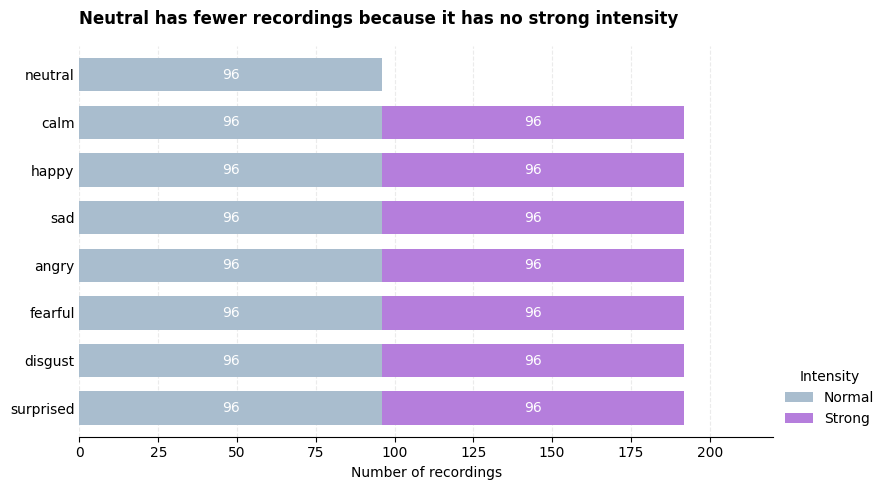

In [ ]:
intensity_counts = pd.crosstab(df['emotion'], df['intensity']).reindex(
    index=EMOTIONS, columns=[1, 2], fill_value=0
)
intensity_counts.columns = ['Normal', 'Strong']
ax = intensity_counts.plot.barh(stacked=True, figsize=(9, 5),
                                color=[MUTED, PURPLE], width=.7)
ax.invert_yaxis()
for bars in ax.containers:
    ax.bar_label(bars, labels=[f'{bar.get_width():.0f}' if bar.get_width() else ''
                               for bar in bars], label_type='center', color='white')
ax.set(title='Neutral has fewer recordings because it has no strong intensity',
       xlabel='Number of recordings', ylabel='', xlim=(0, 220))
ax.grid(axis='x', linestyle='--', alpha=.25)
ax.tick_params(axis='y', length=0)
ax.legend(
    title="Intensity",
    loc="center left",
    bbox_to_anchor=(1, 0.1),
    frameon=False
)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'emotion_by_intensity.png', dpi=170, bbox_inches='tight')
plt.show()

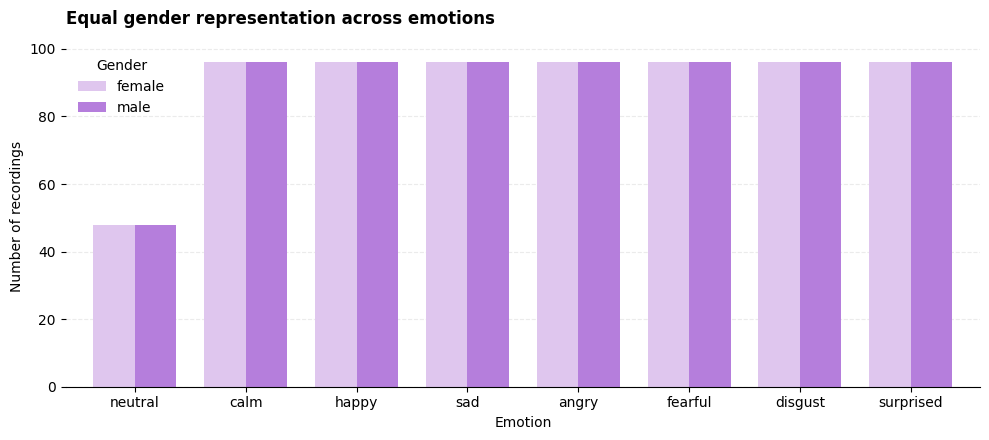

,total,female,male,Normal,Strong
emotion,,,,,
neutral,96,48,48,96,0
calm,192,96,96,96,96
happy,192,96,96,96,96
sad,192,96,96,96,96
angry,192,96,96,96,96
fearful,192,96,96,96,96
disgust,192,96,96,96,96
surprised,192,96,96,96,96


Sample rates:


,count
sample_rate,
48000,1440


In [ ]:
gender_counts = pd.crosstab(df['emotion'], df['gender']).reindex(EMOTIONS)
ax = gender_counts.plot.bar(figsize=(10, 4.5), color=[LAVENDER, PURPLE], width=.75)
ax.set(title='Equal gender representation across emotions',
       xlabel='Emotion', ylabel='Number of recordings')
ax.tick_params(axis='x', rotation=0)
ax.grid(axis='y', linestyle='--', alpha=.25)
ax.legend(title='Gender', frameon=False)
ax.tick_params(axis='x', labelrotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'emotion_by_gender.png', dpi=170, bbox_inches='tight')
plt.show()

display(pd.concat([counts.rename('total'), gender_counts, intensity_counts], axis=1))
print('Sample rates:')
display(df['sample_rate'].value_counts())

**Observation.** Neutral has 96 recordings; each other emotion has 192. Every emotion is represented equally across male and female actors. The missing strong-intensity condition for neutral is a property of the dataset design, not an accidental sampling error.

## 3. Speakers and recording duration

We inspect how evenly recordings are distributed across actors and whether clip duration varies by emotion. Total clip duration includes leading/trailing silence and should not be interpreted directly as speaking rate. Trimming is quantified for the full dataset in notebook `03`.

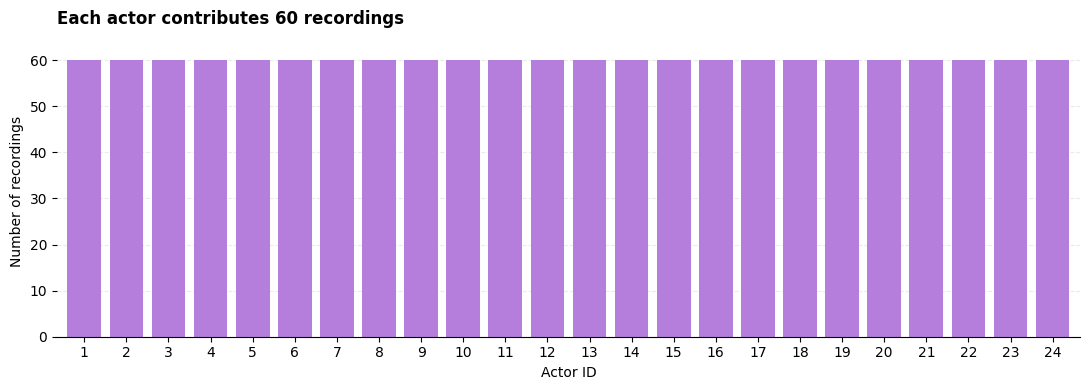

In [ ]:
actor_counts = df.groupby('actor_id').size()
ax = actor_counts.plot.bar(figsize=(11, 4), color=PURPLE, width=.8)
ax.set(title='Each actor contributes 60 recordings',
       xlabel='Actor ID', ylabel='Number of recordings')
ax.grid(axis='y', linestyle='--', alpha=.25)
ax.tick_params(axis='x', labelrotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'recordings_per_actor.png', dpi=170, bbox_inches='tight')
plt.show()

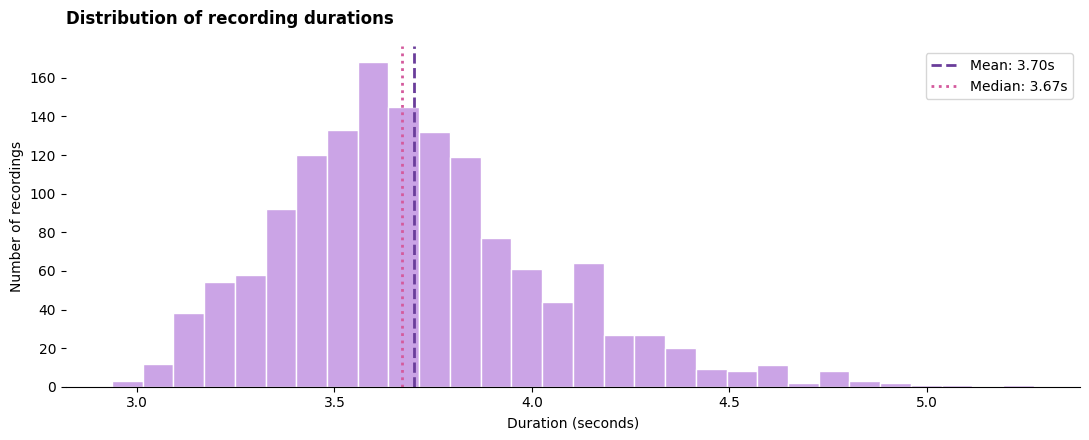

,duration_sec
count,1440.000
mean,3.701
std,0.337
min,2.936
25%,3.470
50%,3.670
75%,3.871
max,5.272


In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.5))

sns.histplot(
    data=df, x="duration_sec",
    bins=30,
    color="#B57EDC", edgecolor= "#FFFFFF", alpha=0.7,
    ax=ax
)

mean = df["duration_sec"].mean()
median = df["duration_sec"].median()

ax.axvline(mean, color="#6A3D9A", ls="--",
           lw=2, label=f"Mean: {mean:.2f}s")
ax.axvline(median, color="#D45A9D", ls=":",
           lw=2, label=f"Median: {median:.2f}s")

ax.set(
    title="Distribution of recording durations",
    xlabel="Duration (seconds)",
    ylabel="Number of recordings"
)
ax.legend()
plt.tight_layout()
plt.show()
display(df['duration_sec'].describe().round(3))

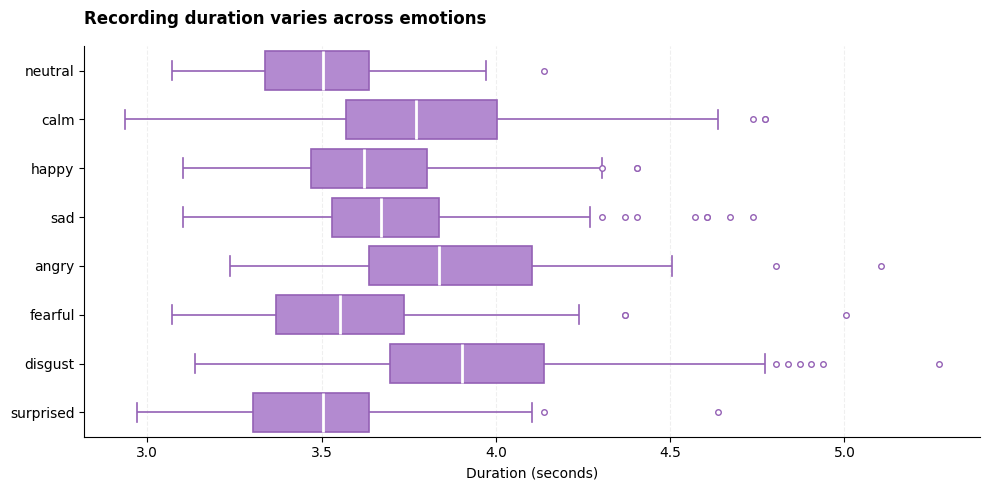

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.boxplot(
    data=df, x="duration_sec", y="emotion",
    color="#B57EDC",
    linewidth=1.2,
    boxprops={"edgecolor": "#9461B5"},
    whiskerprops={"color": "#9461B5"},
    capprops={"color": "#9461B5"},
    medianprops={"color": "#FFFFFF", "linewidth": 2},
    flierprops={"marker": "o", "markersize": 4,
                "markeredgecolor": "#9461B5",
                "markerfacecolor": "white"},
    ax=ax
)

ax.set_title("Recording duration varies across emotions",
             fontweight="bold", loc="left")
ax.set(xlabel="Duration (seconds)", ylabel="")
ax.grid(axis="x", linestyle="--", alpha=0.2)
ax.set_axisbelow(True)


sns.despine()
plt.tight_layout()
plt.show()

**Interpretation.** Compare medians and the overlap between the duration distributions. Differences in recorded duration alone do not establish differences in speech rate because the files also include pauses.

## 4. Save the metadata

The `relative_path` field will connect the original WAV files with notebooks `02` and `03`. Model inputs must exclude filename identifiers, `actor_id`, gender, intensity, and labels.

In [ ]:
METADATA_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(METADATA_PATH, index=False)
print('Metadata saved:', METADATA_PATH)
print('Next: 02_Audio_Signal_Exploration.ipynb')

Metadata saved: /content/drive/MyDrive/speech-emotion-recognition-project-d/data/processed/ravdess_metadata.csv
Next: 02_Audio_Signal_Exploration.ipynb


### Findings to report

- RAVDESS speech includes **1,440 recordings from 24 actors**; this is a structured, acted-emotion dataset.
- Neutral is less frequent because it lacks the strong-intensity condition.
- Each actor has 60 examples, enabling actor-independent evaluation. The split itself is fixed in `04`.
- Differences in clip duration should be interpreted cautiously because recordings include silence.